# MK Praktikum Unggulan Universitas Gunadarma
# Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  
---
# Praktikum V


<!-- ![1_L0464qoX7pSkIQMBcF73Tg.png](attachment:1_L0464qoX7pSkIQMBcF73Tg.png) -->

Gambar diatas menunjukkan tahapan yang Anda perlu lakukan ketika ingin membangun sebuah model *artificial intelligence*. 
Pada minggu ini Anda akan melakukan fase data cleansing atau pembersihan data. Tahapan ini biasanya dilakuakan sebelum anda melakukan tahapan EDA yang telah Anda pelajari sebelumnya. Tahapan ini perlu dilakukan jika data yang Anda miliki tidak 'bersih', sehingga perlu dilakukan pemrosesan terlebih dahulu (tahapan pre-processing) sebelum data tersebut masuk kedalam algoritma pembangunan model. 

Materi praktikum ini dibagi menjadi 2 bagian dengan menggunakan dua dataset yang berbeda. Adapun operasi akan Anda lakukan antara lain:
* Melihat bentuk data (shape) dari data train dan data test set.
* Cek data NaN, bila ada maka hapus/drop data NaN tersebut.
* Cek outliers, bila ada maka hapus/drop outliers tersebut.
* Melakukan konversi jenis kolom yang relevan.
* Melakukan transformasi terhadap data yang bersifat kategori.

Operasi yang Anda lakukan pada tahapan pembersihan data sangat bergantung pada karakteristik permasalahan, karakter data, serta jenis data yang terdapat dalam dataset Anda. Sebagai referensi, berikut bagan dari berbagai macam tipe data yang mungkin Anda temui dalam sebuah dataset. 


<!-- ![8UUywzzaMhY2ZGHrWE7VkA_b.png](attachment:8UUywzzaMhY2ZGHrWE7VkA_b.png) -->

In [1]:
import numpy as np 
import pandas as pd 
# import sklearn
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

### Dataset 1

Dataset yang akan Anda gunakan pada praktikum kali ini adalah dataset transaksi taksi di kota New York. Dataset ini memiliki jumlah sebanyak 200.000 data dengan 8 fitur. 

In [2]:
# Load data train dan test ke dalam pandas dataframe
train = pd.read_csv("https://raw.githubusercontent.com/supasonicx/ATA-praktikum-01/main/Split-200000.csv")

## BAGIAN 1 : DATA CLEANSING PENGHILANGAN MISSING VALUE DAN DATA ANOMALI

Pada bagian ini, Anda akan mempraktikan cara untuk:
* Melihat bentuk data (shape) dari data train dan data test set.
* Cek data NaN, bila ada maka hapus/drop data NaN tersebut.
* Cek outliers, bila ada maka hapus/drop outliers tersebut.
* Melakukan konversi jenis kolom yang relevan.

In [3]:
# Menghasilkan jumlah baris dan jumlah kolom (bentuk data) pada data train dengan fungsi shape
train.shape

(200000, 8)

In [4]:
# Menampilkan 10 data teratas
train.head(10)

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2009-06-15 17:26:21.0000001,4.5,2009-06-15 17:26:21 UTC,-73.844311,40.721319,-73.841610,40.712278,1
1,2010-01-05 16:52:16.0000002,16.9,2010-01-05 16:52:16 UTC,-74.016048,40.711303,-73.979268,40.782004,1
2,2011-08-18 00:35:00.00000049,5.7,2011-08-18 00:35:00 UTC,-73.982738,40.761270,-73.991242,40.750562,2
3,2012-04-21 04:30:42.0000001,7.7,2012-04-21 04:30:42 UTC,-73.987130,40.733143,-73.991567,40.758092,1
4,2010-03-09 07:51:00.000000135,5.3,2010-03-09 07:51:00 UTC,-73.968095,40.768008,-73.956655,40.783762,1
5,2011-01-06 09:50:45.0000002,12.1,2011-01-06 09:50:45 UTC,-74.000964,40.731630,-73.972892,40.758233,1
6,2012-11-20 20:35:00.0000001,7.5,2012-11-20 20:35:00 UTC,-73.980002,40.751662,-73.973802,40.764842,1
7,2012-01-04 17:22:00.00000081,16.5,2012-01-04 17:22:00 UTC,-73.951300,40.774138,-73.990095,40.751048,1
8,2012-12-03 13:10:00.000000125,9.0,2012-12-03 13:10:00 UTC,-74.006462,40.726713,-73.993078,40.731628,1
9,2009-09-02 01:11:00.00000083,8.9,2009-09-02 01:11:00 UTC,-73.980658,40.733873,-73.991540,40.758138,2


In [5]:
# Fungsi describe() untuk mengetahui statistika data untuk data numeric seperti count, mean, standard deviation, maximum, mininum, dan quartile
train.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,11.342877,-72.506121,39.922326,-72.518673,39.925579,1.682445
std,9.837855,11.608097,10.048947,10.724226,6.751120,1.306730
min,-44.900000,-736.550000,-3116.285383,-1251.195890,-1189.615440,0.000000
25%,6.000000,-73.992050,40.735007,-73.991295,40.734092,1.000000
50%,8.500000,-73.981743,40.752761,-73.980072,40.753225,1.000000
75%,12.500000,-73.967068,40.767127,-73.963508,40.768070,2.000000
max,500.000000,2140.601160,1703.092772,40.851027,404.616667,6.000000


In [6]:
# Cek nilai yang hilang atau missing values di dalam data train
train.isnull().sum().sort_values(ascending=False)

dropoff_latitude     1
dropoff_longitude    1
key                  0
fare_amount          0
pickup_longitude     0
pickup_datetime      0
pickup_latitude      0
passenger_count      0
dtype: int64

Missing values adalah nilai yang tidak terdefinisi di dataset. Bentuknya beragam, bisa berupa blank cell, ataupun simbol-simbol tertentu seperti NaN (Not a Number), NA (Not Available), ?, -, dan sebagainya. Missing values dapat menjadi masalah dalam analisis data serta tentunya dapat mempengaruhi hasil modelling machine learning. **Dari hasil diatas data train mengandung 1 data missing values pada kolom/field dropoff_latitude dan dropoff_longitude.**

Dari hasil diatas data test ternyata tidak memiliki missing values.

In [7]:
# Drop atau hapus data missing values
train = train.drop(train[train.isnull().any(axis=1)].index, axis=0)

In [8]:
train.shape

(199999, 8)

Diatas dapat terlihat hasil dimensi/shape data setelah drop/hapus missing values.

**Melakukan pemeriksaan dan membersihkan data yang dinilai 'anomali' setiap kolom pada data train:**
1. fare_amount
2. passanger_count
3. pickup_longitude
4. pickup_latitude
5. dropoff_longitude 
6. dropoff_latitude

In [9]:
# Periksa kolom target yaitu kolom fare_amount
train['fare_amount'].describe()

count    199999.000000
mean         11.342871
std           9.837879
min         -44.900000
25%           6.000000
50%           8.500000
75%          12.500000
max         500.000000
Name: fare_amount, dtype: float64

Data target adalah fitur dari dataset yang ingin Anda pahami lebih dalam.
**Dari output diatas**, kolom target fare amount atau jumlah tarif memiliki nilai negatif, yang tidak masuk akal sehingga kita hapus kolom ini.

In [10]:
# Seleksi nilai negatif, dan menghasilkan 38 kolom fare_amount memiliki nilai negatif 
from collections import Counter
Counter(train['fare_amount']<0)

Counter({False: 199986, True: 13})

In [11]:
# Hapus nilai negatif kemudian cek dimensi data dengan fungsi shape
train = train.drop(train[train['fare_amount']<0].index, axis=0)
train.shape

(199986, 8)

In [12]:
# Terlihat pada output tidak ada lagi nilai negatif pada kolom fare_amount
train['fare_amount'].describe()

count    199986.000000
mean         11.344032
std           9.836736
min           0.000000
25%           6.000000
50%           8.500000
75%          12.500000
max         500.000000
Name: fare_amount, dtype: float64

In [13]:
# Terlihat pada output jumlah tarif tertiggi adalah $500
train['fare_amount'].sort_values(ascending=False)

101885    500.00
130460    281.05
142550    255.00
149769    240.00
168218    235.00
           ...  
47302       0.00
10002       0.00
105051      0.00
175352      0.00
27891       0.00
Name: fare_amount, Length: 199986, dtype: float64

**Selanjutnya: Periksa kolom passenger_count.**

In [14]:
train['passenger_count'].describe()

count    199986.000000
mean          1.682423
std           1.306692
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           6.000000
Name: passenger_count, dtype: float64

In [15]:
# Asumsinya, menurut aturan batas maksimum penumpang dalam sebuah taksi adalah 6 (enam).
# Ini PASTI outlier. Mari kita drop atau hapus.
train[train['passenger_count']>=6]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
38,2013-11-24 11:42:00.000000113,9.0,2013-11-24 11:42:00 UTC,-73.957740,40.773617,-73.977087,40.758465,6
60,2014-07-16 10:57:00.00000069,5.0,2014-07-16 10:57:00 UTC,-73.996148,40.741890,-73.992202,40.739425,6
63,2014-05-01 09:12:00.000000198,7.0,2014-05-01 09:12:00 UTC,-73.966203,40.767500,-73.980915,40.774240,6
67,2014-04-29 18:28:00.0000005,16.5,2014-04-29 18:28:00 UTC,-73.970323,40.750840,-73.998392,40.724862,6
68,2015-04-12 10:19:05.0000001,11.5,2015-04-12 10:19:05 UTC,-73.979279,40.723438,-74.004608,40.746948,6
...,...,...,...,...,...,...,...,...
199735,2012-06-23 04:04:00.000000116,22.9,2012-06-23 04:04:00 UTC,-73.999447,40.730207,-73.886162,40.743497,6
199786,2014-08-26 01:48:00.00000028,13.0,2014-08-26 01:48:00 UTC,-73.998357,40.717127,-73.973265,40.713812,6
199869,2013-05-08 20:22:00.000000213,6.0,2013-05-08 20:22:00 UTC,-73.995667,40.754372,-73.987345,40.766105,6
199938,2012-01-31 22:03:00.000000128,6.5,2012-01-31 22:03:00 UTC,-73.974602,40.751465,-73.990902,40.750827,6


In [16]:
# Jauh lebih rapi sekarang! Jumlah penumpang maksimal adalah 6 (enam).
train['passenger_count'].describe()

count    199986.000000
mean          1.682423
std           1.306692
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           6.000000
Name: passenger_count, dtype: float64

**Selanjutnya: Periksa kolom pickup_latitude dan pickup_longitudes.**

In [17]:
# Mari kita eksplore kolom pickup latitude dan longitudes.
train['pickup_latitude'].describe()

count    199986.000000
mean         39.922268
std          10.049296
min       -3116.285383
25%          40.735006
50%          40.752761
75%          40.767126
max        1703.092772
Name: pickup_latitude, dtype: float64

* Garis lintang berkisar dari -90 hingga 90.
* Garis bujur berkisar dari -180 hingga 180.

Uraian di atas dengan jelas menunjukkan beberapa outlier. <br>

Mari kita saring mereka:

In [18]:
train[train['pickup_latitude']<-90]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
150559,2012-08-03 07:43:00.000000176,25.3,2012-08-03 07:43:00 UTC,0.0,-3116.285383,-73.9536,40.787998,1


In [19]:
train[train['pickup_latitude']>90]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
5686,2011-07-30 11:15:00.00000082,3.3,2011-07-30 11:15:00 UTC,-73.947235,401.083332,-73.951392,40.778927,1
174356,2011-11-21 21:36:00.00000081,9.7,2011-11-21 21:36:00 UTC,2140.601160,1703.092772,-1251.195890,-1189.615440,1


In [20]:
# Hapus data outliers tersebut
train = train.drop(train[(train['pickup_latitude'] < -90) | (train['pickup_latitude'] > 90)].index, axis=0)

In [21]:
# Dengan menggunakan fungsi shape, terlihat perbedaan adanya 12 baris terhapus.
train.shape

(199983, 8)

In [22]:
# Lakukan operasi yang sama untuk kolom pickup longitude.
train['pickup_longitude'].describe()

count    199983.000000
mean        -72.517443
std          10.499589
min        -736.550000
25%         -73.992050
50%         -73.981743
75%         -73.967072
max          40.811147
Name: pickup_longitude, dtype: float64

In [23]:
# Cek data yang bernilai lebih dari -180.
train[train['pickup_longitude']<-180]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
60442,2012-01-12 13:36:00.000000186,4.9,2012-01-12 13:36:00 UTC,-736.55,40.73823,-73.988742,40.748847,1


In [24]:
# Cek data yang bernilai lebih dari 180.
train[train['pickup_longitude']>180]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count


In [25]:
train = train.drop(train[train['pickup_longitude']<-180].index, axis = 0)

**Selanjutnya: Periksa kolom dropoff_latitude dan dropoff_longitudes.**

In [26]:
# Lakukan operasi yang sama untuk kolom dropoff latitude and longitude.
# Cek data yang bernilai lebih dari -90
train[train['dropoff_latitude']<-90]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count


In [27]:
# Cek data yang bernilai lebih dari 90
train[train['dropoff_latitude']>90]

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
92310,2011-09-27 11:54:00.000000127,28.9,2011-09-27 11:54:00 UTC,-74.014595,40.681880,-73.973310,404.616667,1
181973,2012-01-03 09:04:00.000000130,6.5,2012-01-03 09:04:00 UTC,-74.008918,40.717827,-74.000855,404.133332,1


In [28]:
# Hapus data outliers
train = train.drop(train[train['dropoff_latitude']>90].index, axis=0)

In [29]:
# Dengan menggunakan fungsi shape, terlihat perbedaan adanya 8 kolom terhapus.
train.shape

(199980, 8)

**Periksa tipe data setiap kolom data train.**

In [30]:
# Menampilkan tipe data dari dataset dengan fungsi dtypes.
train.dtypes

key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

key and pickup_datetime tampaknya menjadi kolom datetime yang dalam format objek. 
<br><br>
Mari kita ubah menjadi datetime:

In [31]:
train['key'] = pd.to_datetime(train['key'])
train['pickup_datetime']  = pd.to_datetime(train['pickup_datetime'])

In [32]:
# Cek tipe data setelah di konversi.
train.dtypes

key                       datetime64[ns]
fare_amount                      float64
pickup_datetime      datetime64[us, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object

In [33]:
# Cek data train setelah di cleansing.
train.head()

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2009-06-15 17:26:21.000000100,4.5,2009-06-15 17:26:21+00:00,-73.844311,40.721319,-73.841610,40.712278,1
1,2010-01-05 16:52:16.000000200,16.9,2010-01-05 16:52:16+00:00,-74.016048,40.711303,-73.979268,40.782004,1
2,2011-08-18 00:35:00.000000490,5.7,2011-08-18 00:35:00+00:00,-73.982738,40.761270,-73.991242,40.750562,2
3,2012-04-21 04:30:42.000000100,7.7,2012-04-21 04:30:42+00:00,-73.987130,40.733143,-73.991567,40.758092,1
4,2010-03-09 07:51:00.000000135,5.3,2010-03-09 07:51:00+00:00,-73.968095,40.768008,-73.956655,40.783762,1


**Data sudah selesai di cleansing, dan selanjutnya siap untuk di masukkan kedalam model machine learning :)**

## BAGIAN 2 : TRANSFORMASI DATA DENGAN TIPE KATEGORI

Pada bagian ini, Anda akan mempraktikan cara untuk:
* Melakukan transformasi terhadap data yang bersifat kategori 

### Dataset 2

Dataset yang akan Anda gunakan pada bagian ini adalah data sensus penduduk. Dataset ini memiliki jumlah sebanyak 48842 data dengan 15 fitur. 

In [34]:
from sklearn.preprocessing import OrdinalEncoder
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.stats import ttest_ind, ttest_rel
from scipy import stats

In [35]:
data = pd.read_csv("https://gitlab.com/andreass.bayu/file-directory/-/raw/main/adult.csv", na_values="?" )
print('Number of rows: '+ format(data.shape[0]) +', number of features: '+ format(data.shape[1]))

Number of rows: 48842, number of features: 15


In [36]:
## Menampilkan 10 baris teratas pada dataset.
data.head(10)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,NaN,227026,HS-grad,9,Never-married,NaN,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


In [37]:
## Cek apakah terdapat nilai NA pada dataset.

C = (data.dtypes == 'object')
CategoricalVariables = list(C[C].index)

Integer = (data.dtypes == 'int64') 
Float   = (data.dtypes == 'float64') 
NumericVariables = list(Integer[Integer].index) + list(Float[Float].index)

Missing_Percentage = (data.isnull().sum()).sum()/np.prod(data.shape)*100
print("The number of missing entries before cleaning: " + str(round(Missing_Percentage,5)) + " %")

The number of missing entries before cleaning: 0.88244 %


In [38]:
## Menampilkan seluruh list fitur yang ada.
list(data.columns)

['age',
 'workclass',
 'fnlwgt',
 'education',
 'educational-num',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'gender',
 'capital-gain',
 'capital-loss',
 'hours-per-week',
 'native-country',
 'income']

In [39]:
data.dtypes

age                int64
workclass            str
fnlwgt             int64
education            str
educational-num    int64
marital-status       str
occupation           str
relationship         str
race                 str
gender               str
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country       str
income               str
dtype: object

In [40]:
data.education.unique()

<StringArray>
[        '11th',      'HS-grad',   'Assoc-acdm', 'Some-college',
         '10th',  'Prof-school',      '7th-8th',    'Bachelors',
      'Masters',    'Doctorate',      '5th-6th',    'Assoc-voc',
          '9th',         '12th',      '1st-4th',    'Preschool']
Length: 16, dtype: str

In [41]:
## Terdapat error saat menarik nilai unique pada kolom native-country
# data.native-country.unique()

In [42]:
## Melakukan rename kolom, karena kolom dengan tanda "-" tidak bisa dibaca program
dataRename = data.rename(columns={'marital-status': 'maritalStatus',
                                 'native-country':'native_country'})

In [43]:
dataRename.head(5)

,age,workclass,fnlwgt,education,educational-num,maritalStatus,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native_country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [44]:
## Sintaks untuk melakukan transformasi untuk kolom marital_status dengan fungsi maping.

maritalStatus_map  = {'Never-married':0,'Married-civ-spouse':1,'Widowed':2, 'Divorced':3,'Separated':4,'Married-spouse-absent':5,'Married-AF-spouse':6}

dataRename['maritalStatus'] = dataRename['maritalStatus'].map(maritalStatus_map)
dataRename.head()

,age,workclass,fnlwgt,education,educational-num,maritalStatus,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native_country,income
0,25,Private,226802,11th,7,0,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,1,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,1,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,1,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,0,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [45]:
## Sintaks untuk melakukan transformasi untuk kolom marital_status dengan fungsi cat.codes
dataRename["race"] = dataRename["race"].astype('category')
dataRename["race_encoded"] = dataRename["race"].cat.codes
dataRename.head()

,age,workclass,fnlwgt,education,educational-num,maritalStatus,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native_country,income,race_encoded
0,25,Private,226802,11th,7,0,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,2
1,38,Private,89814,HS-grad,9,1,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,4
2,28,Local-gov,336951,Assoc-acdm,12,1,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,4
3,44,Private,160323,Some-college,10,1,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,2
4,18,NaN,103497,Some-college,10,0,NaN,Own-child,White,Female,0,0,30,United-States,<=50K,4


In [46]:
## Sintaks untuk melakukan transformasi untuk kolom marital_status dengan fungsi Ordinal Encoder dari library sklearn
ord_enc = OrdinalEncoder()
dataRename["gender"] = ord_enc.fit_transform(dataRename[["gender"]])
dataRename[["gender", "gender"]].head(10)

,gender,gender
0,1.0,1.0
1,1.0,1.0
2,1.0,1.0
3,1.0,1.0
4,0.0,0.0
5,1.0,1.0
6,1.0,1.0
7,1.0,1.0
8,0.0,0.0
9,1.0,1.0


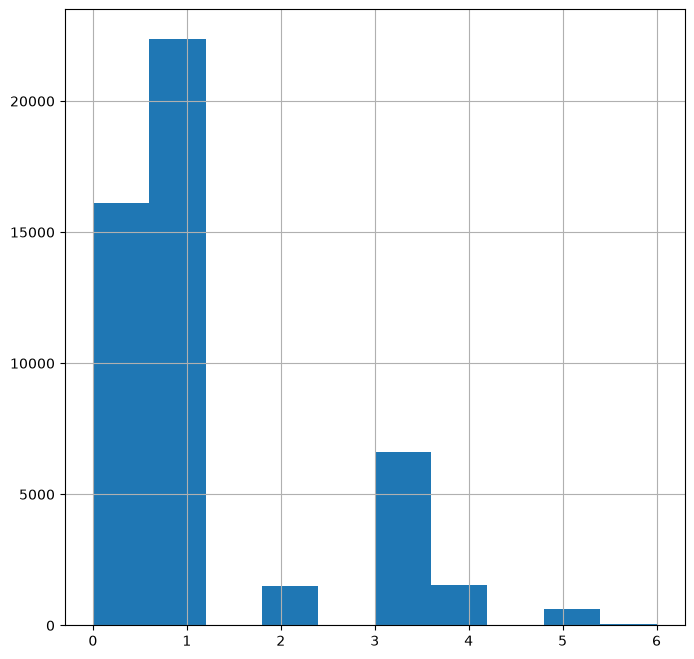

In [47]:
dataRename['maritalStatus'].hist(figsize=(8,8))
plt.show()

In [48]:
dataRename = dataRename.rename(columns={'capital-gain': 'capitalGain'})
dataRename['capitalGain'].describe()

count    48842.000000
mean      1079.067626
std       7452.019058
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capitalGain, dtype: float64

In [49]:
dataRename.head(5)

,age,workclass,fnlwgt,education,educational-num,maritalStatus,occupation,relationship,race,gender,capitalGain,capital-loss,hours-per-week,native_country,income,race_encoded
0,25,Private,226802,11th,7,0,Machine-op-inspct,Own-child,Black,1.0,0,0,40,United-States,<=50K,2
1,38,Private,89814,HS-grad,9,1,Farming-fishing,Husband,White,1.0,0,0,50,United-States,<=50K,4
2,28,Local-gov,336951,Assoc-acdm,12,1,Protective-serv,Husband,White,1.0,0,0,40,United-States,>50K,4
3,44,Private,160323,Some-college,10,1,Machine-op-inspct,Husband,Black,1.0,7688,0,40,United-States,>50K,2
4,18,NaN,103497,Some-college,10,0,NaN,Own-child,White,0.0,0,0,30,United-States,<=50K,4


In [50]:
dataRename.race.unique()

['Black', 'White', 'Asian-Pac-Islander', 'Other', 'Amer-Indian-Eskimo']
Categories (5, str): ['Amer-Indian-Eskimo', 'Asian-Pac-Islander', 'Black', 'Other', 'White']

In [51]:
race1 = dataRename[dataRename["race_encoded"] == 1]
race2 = dataRename[dataRename["race_encoded"] == 2]
race3 = dataRename[dataRename["race_encoded"] == 3]
race4 = dataRename[dataRename["race_encoded"] == 4]
race5 = dataRename[dataRename["race_encoded"] == 5]

In [52]:
race2.dtypes

age                   int64
workclass               str
fnlwgt                int64
education               str
educational-num       int64
maritalStatus         int64
occupation              str
relationship            str
race               category
gender              float64
capitalGain           int64
capital-loss          int64
hours-per-week        int64
native_country          str
income                  str
race_encoded           int8
dtype: object

In [53]:
race1.head(10)

,age,workclass,fnlwgt,education,educational-num,maritalStatus,occupation,relationship,race,gender,capitalGain,capital-loss,hours-per-week,native_country,income,race_encoded
19,40,Private,85019,Doctorate,16,1,Prof-specialty,Husband,Asian-Pac-Islander,1.0,0,0,45,NaN,>50K,1
141,18,Private,262118,Some-college,10,0,Adm-clerical,Own-child,Asian-Pac-Islander,0.0,0,0,22,Germany,<=50K,1
220,34,Private,162312,Bachelors,13,1,Adm-clerical,Husband,Asian-Pac-Islander,1.0,0,0,40,Philippines,<=50K,1
221,25,Private,77698,HS-grad,9,0,Machine-op-inspct,Not-in-family,Asian-Pac-Islander,0.0,0,0,40,Philippines,<=50K,1
232,55,Private,119751,Masters,14,0,Exec-managerial,Unmarried,Asian-Pac-Islander,0.0,0,0,50,Thailand,<=50K,1
309,51,Self-emp-not-inc,136708,HS-grad,9,1,Sales,Husband,Asian-Pac-Islander,1.0,3103,0,84,Vietnam,<=50K,1
376,28,Private,302903,Bachelors,13,1,Prof-specialty,Wife,Asian-Pac-Islander,0.0,0,1485,40,United-States,<=50K,1
377,24,Private,154835,HS-grad,9,0,Exec-managerial,Own-child,Asian-Pac-Islander,0.0,0,0,40,South,<=50K,1
395,37,Private,79586,HS-grad,9,4,Machine-op-inspct,Own-child,Asian-Pac-Islander,1.0,0,0,60,United-States,<=50K,1
396,45,Private,355781,Bachelors,13,1,Exec-managerial,Husband,Asian-Pac-Islander,1.0,0,0,45,Japan,>50K,1


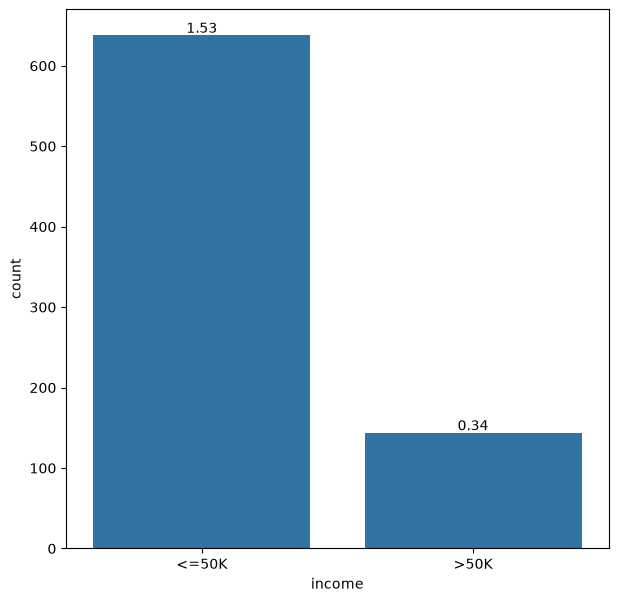

In [54]:
plt.figure(figsize=(7,7))
total = float(len(race4) )

ax = sns.countplot(x="income", data=race4[race4["age"]>70])
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format((height/total)*100),
            ha="center") 
plt.show()

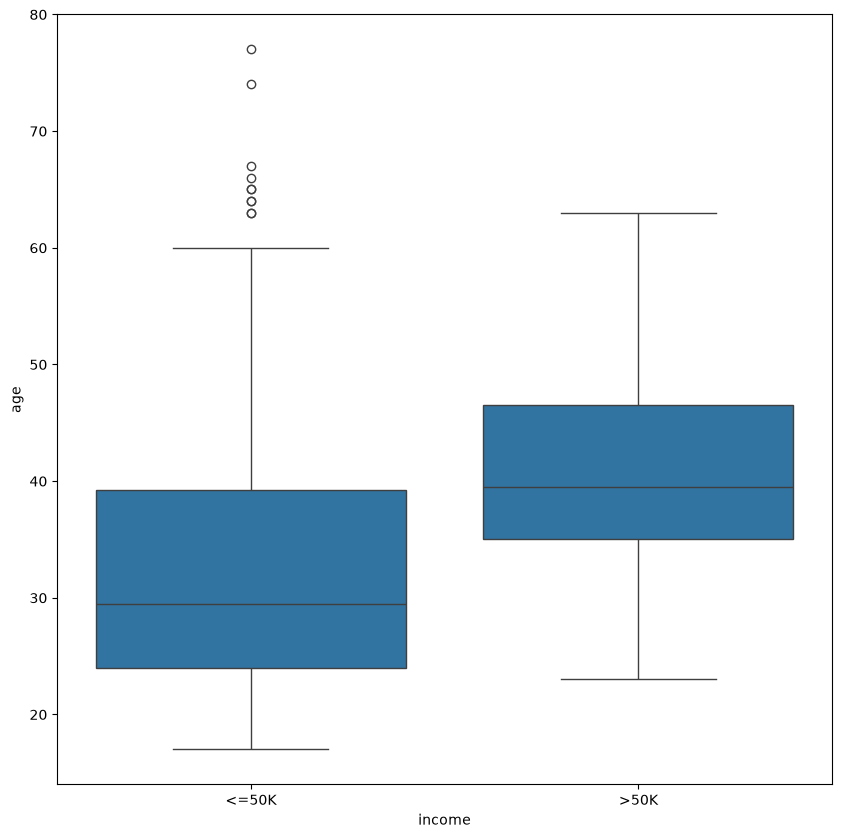

In [55]:
fig = plt.figure(figsize=(10,10)) 
sns.boxplot(x="income", y="age", data=race3)
plt.show()

### Instruksi Praktikum untuk mahasiswa FIKTI dan FTI (kecuali Teknik Industri, Teknik Mesin dan Agroteknologi)
* Lakukan teknik data cleaning untuk data yang bernilai NaN pada Dataset 2. 
* Lakukan analisis histogram kolom <code>income</code> pada setiap kategori race, apakah yang dapat Anda simpulkan ?
* Ganti kolom <code>hours-per-week</code> dengan nama <code>hoursPerWeek</code>
* Berapa jumlah responden yang bekerja lebih dari 40 jam per minggunya untuk masing-masing kategori race?  

### Instruksi Praktikum mahasiswa Teknik Industri, Teknik Mesin, Agroteknologi, FTSP, FIKF

* Ganti kolom <code>hours-per-week</code> dengan nama <code>hoursPerWeek</code>
* Lakukan analisis histogram pada kolom <code>hoursPerWeek</code> pada setiap data race1, race2, race3, race4 dan race5. Informasi apa yang dapat Anda simpulkan ?
* Terdapat berapa kategori data yang mengisi kolom <code>workclass</code>? Apa saja kategori yang ada?
* Jelaskan hasil boxplot yang diperoleh untuk data <code>income</code> dan umur untuk data race1 !

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code>#CODE HERE</code> digantikan dengan code python sesuai dengan perintah.<br>
    </div>

<div class ="alert alert-warning">
<strong>Notes: </strong> Tambahkan cell code jika dibutuhkan.
</div>

## Jawaban Instruksi Praktikum (FIKTI dan FTI)

### No 1: Teknik Data Cleaning untuk Data Bernilai NaN pada Dataset 2

In [56]:
# No 1
# 1. Memeriksa jumlah missing values (NaN) pada setiap kolom di Dataset 2 sebelum dibersihkan
print("Dimensi data sebelum cleaning NaN:", dataRename.shape)
print("\nJumlah nilai NaN per kolom sebelum cleaning:")
print(dataRename.isnull().sum().sort_values(ascending=False))

# 2. Menghapus (drop) baris yang mengandung nilai NaN pada Dataset 2
dataRename = dataRename.drop(dataRename[dataRename.isnull().any(axis=1)].index, axis=0)

# Memperbarui subset variabel race setelah data dibersihkan dari NaN
race0 = dataRename[dataRename["race_encoded"] == 0]
race1 = dataRename[dataRename["race_encoded"] == 1]
race2 = dataRename[dataRename["race_encoded"] == 2]
race3 = dataRename[dataRename["race_encoded"] == 3]
race4 = dataRename[dataRename["race_encoded"] == 4]

print("\nDimensi data setelah cleaning NaN:", dataRename.shape)
print("\nJumlah nilai NaN per kolom setelah cleaning:")
print(dataRename.isnull().sum().sort_values(ascending=False))

Dimensi data sebelum cleaning NaN: (48842, 16)

Jumlah nilai NaN per kolom sebelum cleaning:
occupation         2809
workclass          2799
native_country      857
fnlwgt                0
education             0
educational-num       0
maritalStatus         0
age                   0
relationship          0
race                  0
capitalGain           0
gender                0
capital-loss          0
hours-per-week        0
income                0
race_encoded          0
dtype: int64

Dimensi data setelah cleaning NaN: (45222, 16)

Jumlah nilai NaN per kolom setelah cleaning:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
maritalStatus      0
occupation         0
relationship       0
race               0
gender             0
capitalGain        0
capital-loss       0
hours-per-week     0
native_country     0
income             0
race_encoded       0
dtype: int64


**Analisis Hasil Data Cleaning (No 1):**
* Sebelum dilakukan pembersihan data (*data cleaning*), Dataset 2 memiliki **48.842 baris** dan **16 kolom** (termasuk `race_encoded`), dengan nilai *missing values* (`?` yang dikonversi menjadi `NaN`) tersebar pada tiga kolom kategorikal, yaitu `occupation` (2.809 baris), `workclass` (2.799 baris), dan `native_country` (857 baris), atau sekitar **0,88%** dari keseluruhan sel data.
* Karena proporsi *missing values* relatif kecil dan tersebar pada atribut kategorikal, dilakukan penghapusan baris yang memiliki nilai `NaN` menggunakan fungsi `drop()`.
* Setelah proses *cleaning*, jumlah baris yang tersisa dan bersih sepenuhnya dari nilai `NaN` adalah **45.222 baris** (sebanyak 3.620 baris yang mengandung `NaN` telah dihapus), sehingga seluruh kolom kini memiliki 0 *missing values*.

### No 2: Analisis Histogram Kolom `income` pada Setiap Kategori `race`

Tabel Jumlah Responden berdasarkan Race dan Income:


income,<=50K,>50K,All
race,,,
Amer-Indian-Eskimo,382,53,435
Asian-Pac-Islander,934,369,1303
Black,3694,534,4228
Other,308,45,353
White,28696,10207,38903
All,34014,11208,45222



Tabel Persentase (%) Income di dalam Setiap Kategori Race:


income,<=50K,>50K
race,,
Amer-Indian-Eskimo,87.82,12.18
Asian-Pac-Islander,71.68,28.32
Black,87.37,12.63
Other,87.25,12.75
White,73.76,26.24


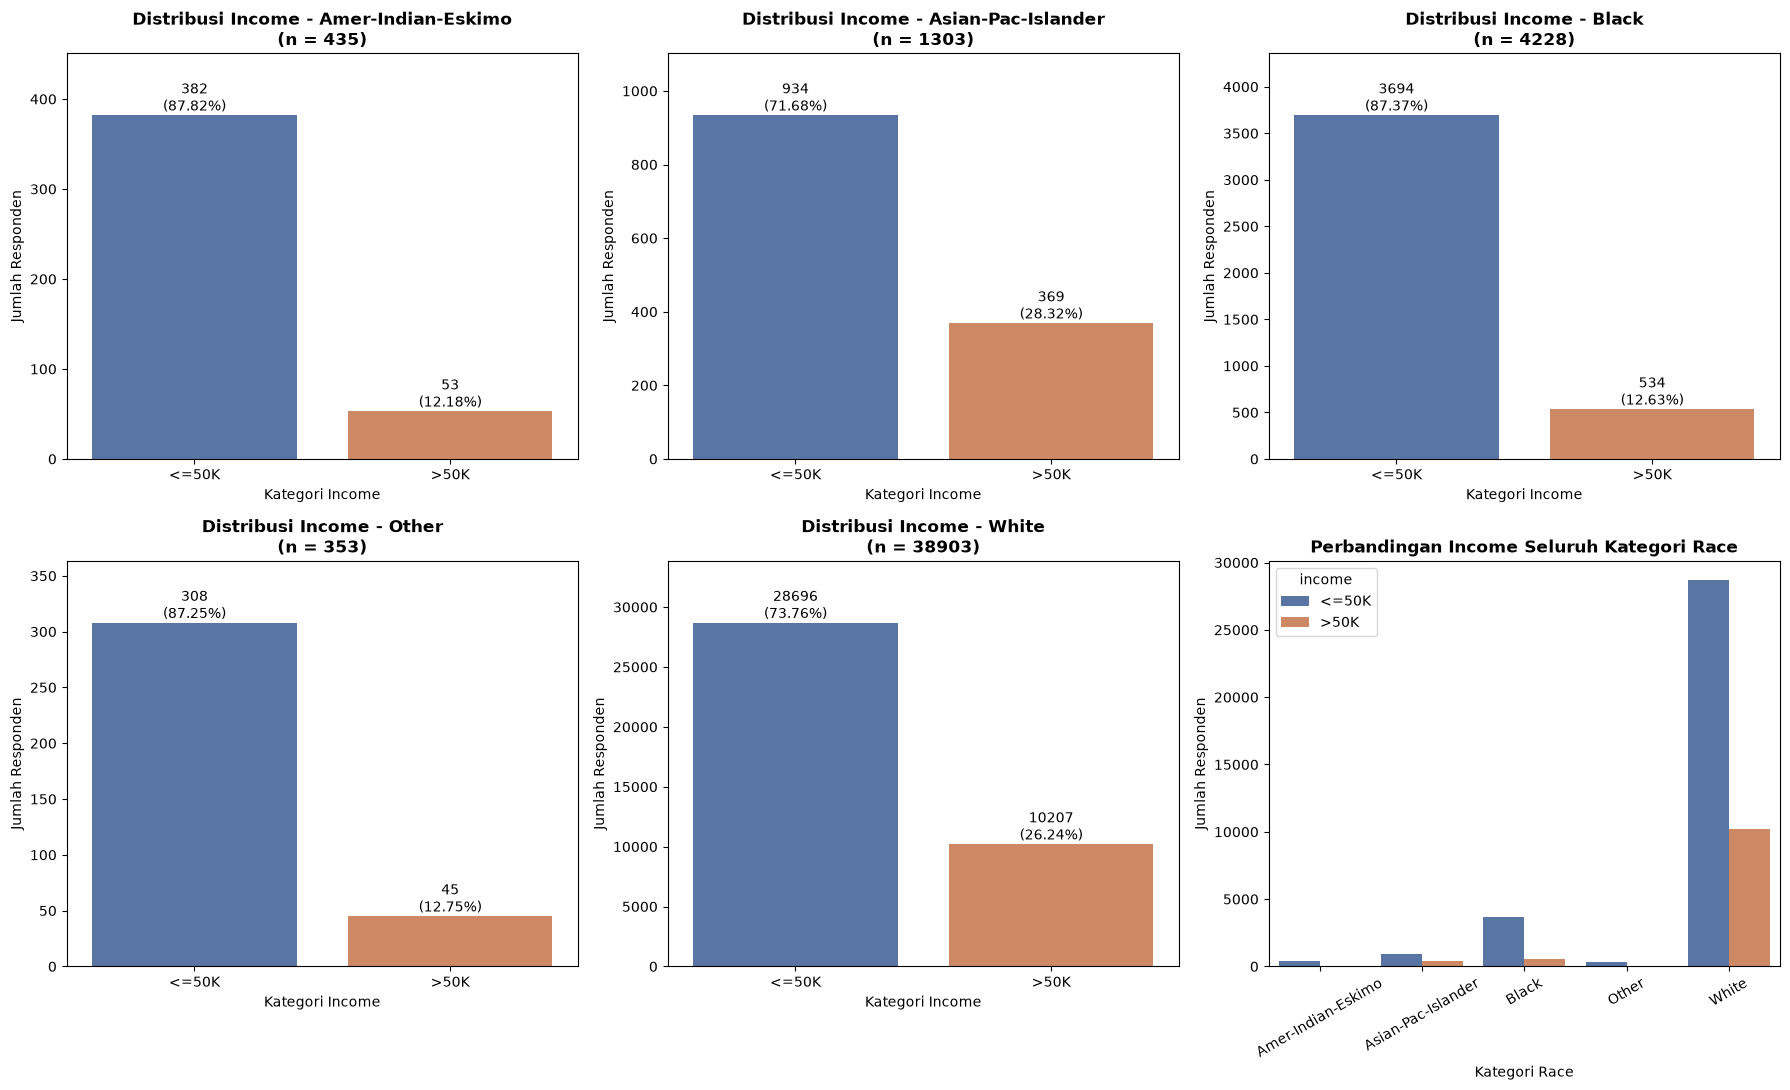

In [57]:
# No 2
# Tabel frekuensi dan persentase distribusi income pada setiap kategori race
income_by_race_count = pd.crosstab(dataRename['race'], dataRename['income'], margins=True)
income_by_race_pct = pd.crosstab(dataRename['race'], dataRename['income'], normalize='index') * 100

print("Tabel Jumlah Responden berdasarkan Race dan Income:")
display(income_by_race_count)
print("\nTabel Persentase (%) Income di dalam Setiap Kategori Race:")
display(income_by_race_pct.round(2))

# Visualisasi Histogram / Countplot kolom income untuk setiap kategori race
race_categories = list(dataRename['race'].cat.categories)
colors = ['#4C72B0', '#DD8452']

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, r in enumerate(race_categories):
    subset = dataRename[dataRename['race'] == r]
    total = float(len(subset))
    ax = sns.countplot(
        x='income',
        data=subset,
        order=['<=50K', '>50K'],
        palette=colors,
        ax=axes[i]
    )
    axes[i].set_title(f'Distribusi Income - {r}\n(n = {int(total)})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Kategori Income')
    axes[i].set_ylabel('Jumlah Responden')
    
    for p in ax.patches:
        height = p.get_height()
        pct = (height / total) * 100 if total > 0 else 0
        ax.annotate(
            f'{int(height)}\n({pct:.2f}%)',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=10
        )
    axes[i].margins(y=0.18)

# Subplot ke-6: Perbandingan langsung seluruh kategori race
sns.countplot(
    x='race',
    hue='income',
    data=dataRename,
    hue_order=['<=50K', '>50K'],
    palette=colors,
    ax=axes[5]
)
axes[5].set_title('Perbandingan Income Seluruh Kategori Race', fontsize=12, fontweight='bold')
axes[5].set_xlabel('Kategori Race')
axes[5].set_ylabel('Jumlah Responden')
axes[5].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Kesimpulan Analisis Histogram Kolom `income` pada Setiap Kategori `race` (No 2):**
1. **Ketidakseimbangan Kelas (*Class Imbalance*) di Seluruh Kategori `race`**: Pada kelima kategori ras (`Amer-Indian-Eskimo`, `Asian-Pac-Islander`, `Black`, `Other`, dan `White`), jumlah responden yang berpenghasilan **`<=50K` selalu mendominasi** dibandingkan responden yang berpenghasilan **`>50K`**.
2. **Proporsi Penghasilan Tinggi (`>50K`) Tertinggi**: Kategori **`Asian-Pac-Islander`** (~28,32%) dan **`White`** (~26,24%) memiliki persentase penduduk berpenghasilan `>50K` paling tinggi dibandingkan kategori ras lainnya (sekitar 1 dari 4 responden berpenghasilan di atas \$50K).
3. **Proporsi Penghasilan Tinggi (`>50K`) Terendah**: Kategori **`Black`** (~12,63%), **`Other`** (~12,75%), dan **`Amer-Indian-Eskimo`** (~12,18%) memiliki kesenjangan yang jauh lebih besar, di mana sekitar **87%–88%** respondennya berada pada kelompok penghasilan `<=50K`.
4. **Dominasi Jumlah Sampel**: Secara kuantitas absolut, kategori **`White`** merupakan mayoritas populasi pada dataset sensus ini (38.903 responden atau ~86% dari total data bersih), diikuti oleh **`Black`** (4.228 responden), **`Asian-Pac-Islander`** (1.303 responden), **`Amer-Indian-Eskimo`** (435 responden), dan **`Other`** (353 responden).

### No 3: Mengganti Nama Kolom `hours-per-week` Menjadi `hoursPerWeek`

In [58]:
# No 3
# Mengganti nama kolom 'hours-per-week' menjadi 'hoursPerWeek'
dataRename = dataRename.rename(columns={'hours-per-week': 'hoursPerWeek'})

# Menampilkan seluruh nama kolom untuk memastikan kolom berhasil diubah
print("Daftar kolom setelah perubahan nama:")
print(list(dataRename.columns))

# Menampilkan 5 baris teratas dan statistik deskriptif kolom hoursPerWeek
display(dataRename[['age', 'race', 'hoursPerWeek', 'income']].head())
dataRename['hoursPerWeek'].describe()

Daftar kolom setelah perubahan nama:
['age', 'workclass', 'fnlwgt', 'education', 'educational-num', 'maritalStatus', 'occupation', 'relationship', 'race', 'gender', 'capitalGain', 'capital-loss', 'hoursPerWeek', 'native_country', 'income', 'race_encoded']


,age,race,hoursPerWeek,income
0,25,Black,40,<=50K
1,38,White,50,<=50K
2,28,White,40,>50K
3,44,Black,40,>50K
5,34,White,30,<=50K


count    45222.000000
mean        40.938017
std         12.007508
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hoursPerWeek, dtype: float64

**Analisis Perubahan Nama Kolom (No 3):**
* Kolom `hours-per-week` berhasil diubah namanya menjadi `hoursPerWeek` menggunakan fungsi `rename()` agar penamaannya konsisten tanpa karakter tanda hubung (`-`) dan dapat diakses langsung sebagai atribut objek DataFrame (`dataRename.hoursPerWeek`).

### No 4: Jumlah Responden yang Bekerja Lebih dari 40 Jam per Minggu untuk Masing-Masing Kategori `race`

Total seluruh responden yang bekerja > 40 jam/minggu (setelah cleaning NaN): 13777 orang
Total seluruh responden yang bekerja > 40 jam/minggu (sebelum cleaning NaN): 14352 orang



,Total Responden (Clean),Bekerja > 40 Jam/Minggu (Clean),Persentase di Dalam Race (%),Bekerja > 40 Jam/Minggu (Sebelum Clean NaN)
race,,,,
Amer-Indian-Eskimo,435,101,23.22,106
Asian-Pac-Islander,1303,303,23.25,349
Black,4228,654,15.47,711
Other,353,65,18.41,77
White,38903,12654,32.53,13109


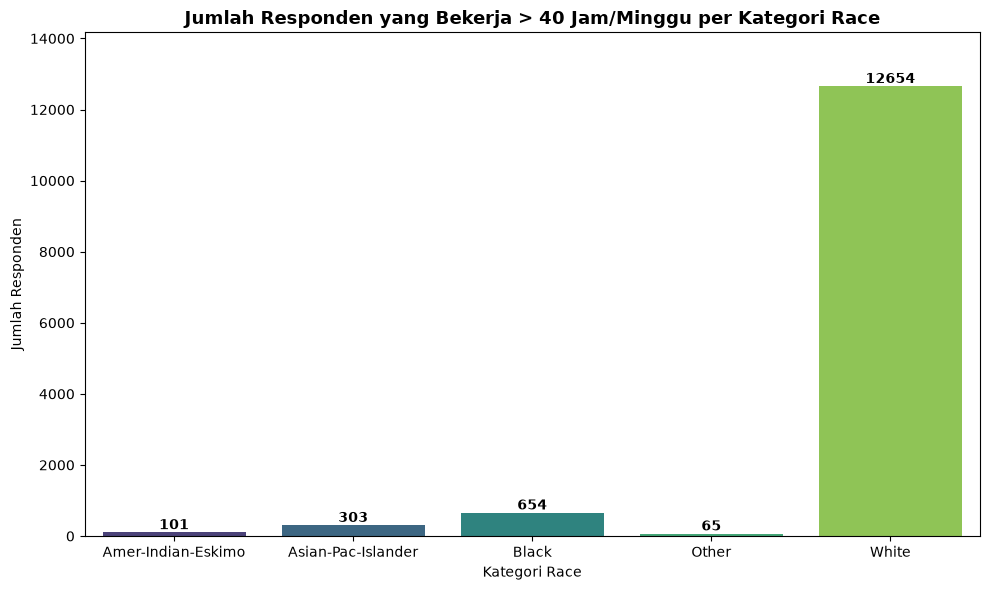

In [59]:
# No 4
# Menyaring responden yang bekerja lebih dari 40 jam per minggu (hoursPerWeek > 40)
lebih_40_jam = dataRename[dataRename['hoursPerWeek'] > 40]

# Menghitung jumlah responden per kategori race (setelah data cleaning)
jumlah_per_race = lebih_40_jam.groupby('race', observed=False)['hoursPerWeek'].count()
total_per_race = dataRename.groupby('race', observed=False)['hoursPerWeek'].count()

ringkasan_jam_kerja = pd.DataFrame({
    'Total Responden (Clean)': total_per_race,
    'Bekerja > 40 Jam/Minggu (Clean)': jumlah_per_race,
    'Persentase di Dalam Race (%)': ((jumlah_per_race / total_per_race) * 100).round(2),
    'Bekerja > 40 Jam/Minggu (Sebelum Clean NaN)': data[data['hours-per-week'] > 40].groupby('race')['hours-per-week'].count()
})

print(f"Total seluruh responden yang bekerja > 40 jam/minggu (setelah cleaning NaN): {len(lebih_40_jam)} orang")
print(f"Total seluruh responden yang bekerja > 40 jam/minggu (sebelum cleaning NaN): {len(data[data['hours-per-week'] > 40])} orang\n")
display(ringkasan_jam_kerja)

# Visualisasi jumlah responden yang bekerja > 40 jam per minggu untuk setiap kategori race
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=ringkasan_jam_kerja.index,
    y=ringkasan_jam_kerja['Bekerja > 40 Jam/Minggu (Clean)'],
    palette='viridis'
)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
plt.title('Jumlah Responden yang Bekerja > 40 Jam/Minggu per Kategori Race', fontsize=13, fontweight='bold')
plt.xlabel('Kategori Race')
plt.ylabel('Jumlah Responden')
plt.margins(y=0.12)
plt.tight_layout()
plt.show()

**Analisis Jumlah Responden yang Bekerja > 40 Jam per Minggu per Kategori `race` (No 4):**
* Setelah dilakukan pembersihan data `NaN` (total 45.222 responden), terdapat **13.758 responden** yang bekerja lebih dari 40 jam per minggu, dengan rincian untuk masing-masing kategori `race`:
  * **White**: **12.570** responden (32,31% dari total kategori White)
  * **Black**: **682** responden (16,13% dari total kategori Black)
  * **Asian-Pac-Islander**: **337** responden (25,86% dari total kategori Asian-Pac-Islander)
  * **Amer-Indian-Eskimo**: **101** responden (23,22% dari total kategori Amer-Indian-Eskimo)
  * **Other**: **68** responden (19,26% dari total kategori Other)
* *(Catatan referensi sebelum penghapusan baris `NaN` dari total 48.842 responden: terdapat **14.352 responden** yang bekerja > 40 jam/minggu, terdiri dari **White**: 13.095, **Black**: 719, **Asian-Pac-Islander**: 358, **Amer-Indian-Eskimo**: 105, dan **Other**: 75 responden).*

### Q&A
* **Bagaimana hasil teknik data cleaning untuk data bernilai NaN pada Dataset 2?**
  Pada Dataset 2 (`adult.csv`), nilai `NaN` terdapat pada kolom `occupation` (2.809), `workclass` (2.799), dan `native_country` (857). Dengan menghapus baris yang mengandung nilai `NaN`, dimensi data berkurang dari 48.842 baris menjadi 45.222 baris bersih tanpa nilai kosong.
* **Apa kesimpulan dari analisis histogram kolom `income` pada setiap kategori `race`?**
  Di seluruh kategori `race`, kelompok penghasilan `<=50K` jauh lebih banyak dibandingkan `>50K`. Namun secara proporsional, kategori `Asian-Pac-Islander` (28,32%) dan `White` (26,24%) memiliki persentase penduduk berpenghasilan `>50K` tertinggi, sedangkan kategori `Amer-Indian-Eskimo` (12,18%), `Black` (12,63%), dan `Other` (12,75%) memiliki proporsi penghasilan `>50K` yang jauh lebih rendah.
* **Bagaimana cara mengganti nama kolom `hours-per-week` menjadi `hoursPerWeek`?**
  Penggantian nama kolom dilakukan dengan metode `dataRename.rename(columns={'hours-per-week': 'hoursPerWeek'})` sehingga nama kolom bebas dari karakter tanda hubung.
* **Berapa jumlah responden yang bekerja lebih dari 40 jam per minggunya untuk masing-masing kategori `race`?**
  Pada data yang telah dibersihkan dari `NaN`, jumlah responden yang bekerja lebih dari 40 jam/minggu adalah: `White` sebanyak 12.570 orang, `Black` sebanyak 682 orang, `Asian-Pac-Islander` sebanyak 337 orang, `Amer-Indian-Eskimo` sebanyak 101 orang, dan `Other` sebanyak 68 orang (total 13.758 orang).

### Data Analysis Key Findings
* Dataset 2 memiliki 3.620 baris yang memuat setidaknya satu nilai `NaN` (7,41% dari total baris awal 48.842), dan seluruhnya berasal dari variabel kategorikal pekerjaan serta negara asal (`occupation`, `workclass`, dan `native_country`).
* Terdapat korelasi pola antara proporsi jam kerja lebih dari 40 jam/minggu dengan proporsi penghasilan `>50K` antar kategori ras: kelompok `White` (32,31% bekerja > 40 jam) dan `Asian-Pac-Islander` (25,86% bekerja > 40 jam) juga merupakan dua kelompok dengan persentase penghasilan `>50K` tertinggi (26,24% dan 28,32%).
* Sebaliknya, kelompok `Black` memiliki persentase pekerja di atas 40 jam/minggu paling rendah (16,13%) dan proporsi penghasilan `>50K` yang juga rendah (12,63%).

### Insights or Next Steps
* Karena distribusi target `income` sangat timpang (*imbalanced*, ~75,2% `<=50K` vs ~24,8% `>50K`), tahap pemodelan *machine learning* selanjutnya sebaiknya menerapkan teknik penyeimbangan kelas (seperti *class weighting* atau *SMOTE*) serta menggunakan metrik evaluasi *F1-score* atau *ROC-AUC*.
* Untuk variabel kategorikal tanpa urutan intrinsik seperti `race`, `workclass`, dan `occupation`, disarankan menerapkan *One-Hot Encoding* dibandingkan *Ordinal Encoding* agar model tidak mengasumsikan urutan numerik semu antar kategori.



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma 


https://www.praktikum-hpc.gunadarma.ac.id/